## Notebook to retreive the general structure of the APIs used in the project

### Open-Meteo API

In [6]:
import requests

# endpoint for the Open-Meteo API
url = "https://archive-api.open-meteo.com/v1/archive"

# parameters for the API request, we define them separately to integrate a loop later
params = {
    "latitude": 40.4168,
    "longitude": -3.7038,
    "start_date": "2025-01-01",
    "end_date": "2025-01-02",
    "hourly": "temperature_2m,apparent_temperature,shortwave_radiation",
    "timezone": "UTC",
}

# GET request
response = requests.get(url, params=params, timeout=15)

# Check for successful response
print(f"Status Code: {response.status_code}")
if response.status_code == 200:
    data = response.json()
    print("Root keys:", list(data.keys()))
    print("Keys in hourly:", list(data["hourly"].keys()))
    print("Total hours:", len(data["hourly"]["time"]))
    print("Sample:", data["hourly"]["time"][0], data["hourly"]["temperature_2m"][0])
else:
    print("Error:", response.status_code, response.text)



Status Code: 200
Root keys: ['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly']
Keys in hourly: ['time', 'temperature_2m', 'apparent_temperature', 'shortwave_radiation']
Total hours: 48
Sample: 2025-01-01T00:00 0.3


### ReDATA API

In [7]:
import requests

# endpoint for the Red Eléctrica de España API
url = "https://apidatos.ree.es/en/datos/demanda/evolucion"

# parameters for the API request
params = {
    "start_date": "2025-01-01T00:00",
    "end_date": "2025-01-02T23:59",
    "time_trunc": "hour",
    "geo_trunc": "electric_system",
    "geo_limit": "peninsular",
    "geo_ids": "8741"
}

# headers for the API request
headers = {"Accept": "application/json", "User-Agent": "Mozilla/5.0"}

# GET request
response = requests.get(url, params=params, headers=headers, timeout=15)

# Check for successful response
print(f"Status Code: {response.status_code}")
if response.status_code == 200:
    data = response.json()
    
    # Print the root keys of the JSON response
    print("1. Root keys:", list(data.keys()))
    
    # Capa 2: Qué series vienen dentro de 'included'
    included = data["included"]
    print(f"2. Number of series in 'included': {len(included)}")
    for i, serie in enumerate(included):
        print(f"   Serie [{i}] -> type: {serie['type']} | title: {serie['attributes']['title']}")
    
    # Capa 3: Inspeccionar los valores de la primera serie
    values = included[0]["attributes"]["values"]
    print(f"\n3. Total records: {len(values)}")
    print("   First record:", values[0])
    print("   Last record:", values[-1])
else:
    print("Error:", response.text)

Status Code: 200
1. Root keys: ['data', 'included']
2. Number of series in 'included': 1
   Serie [0] -> type: Demand | title: Demand

3. Total records: 48
   First record: {'value': 23004.178, 'percentage': 1, 'datetime': '2025-01-01T00:00:00.000+01:00'}
   Last record: {'value': 28372.538, 'percentage': 1, 'datetime': '2025-01-02T23:00:00.000+01:00'}


## Data Quality Check


In [1]:
import pandas as pd
from src.config import DEMAND_RAW_PATH, WEATHER_RAW_PATH

# Load raw parquet files 
df_demand_raw = pd.read_parquet(DEMAND_RAW_PATH)
df_weather_raw = pd.read_parquet(WEATHER_RAW_PATH)

print(" DEMAND RAW SUMMARY ")
print(f"Shape; {df_demand_raw.shape}")
print(f"Null values:\n{df_demand_raw.isna().sum()}\n")
print(f"Duplicate timestamps: {df_demand_raw['datetime'].duplicated().sum()}")
display(df_demand_raw.head(3))
display(df_demand_raw.tail(3))

print("\n WEATHER RAW SUMMARY ")
print(f"Shape: {df_weather_raw.shape}")
print(f"Null values:\n{df_weather_raw.isna().sum()}\n")
print(f"Rows per city:\n{df_weather_raw['city'].value_counts()}")
display(df_weather_raw.head(3))

 DEMAND RAW SUMMARY 
Shape; (42360, 3)
Null values:
value         0
percentage    0
datetime      0
dtype: int64

Duplicate timestamps: 0


,value,percentage,datetime
0,21302.252,1,2022-01-01T00:00:00.000+01:00
1,20605.178,1,2022-01-01T01:00:00.000+01:00
2,19293.080,1,2022-01-01T02:00:00.000+01:00


,value,percentage,datetime
42357,26168.55,1,2026-10-31T21:00:00.000+01:00
42358,24369.21,1,2026-10-31T22:00:00.000+01:00
42359,22822.13,1,2026-10-31T23:00:00.000+01:00



 WEATHER RAW SUMMARY 
Shape: (211800, 6)
Null values:
time                    0
temperature_2m          0
apparent_temperature    0
shortwave_radiation     0
city                    0
weight                  0
dtype: int64

Rows per city:
city
madrid       42360
barcelona    42360
valencia     42360
sevilla      42360
bilbao       42360
Name: count, dtype: int64


,time,temperature_2m,apparent_temperature,shortwave_radiation,city,weight
0,2022-01-01T00:00,3.9,0.7,0.0,madrid,0.35
1,2022-01-01T01:00,3.3,-0.0,0.0,madrid,0.35
2,2022-01-01T02:00,2.8,-0.5,0.0,madrid,0.35


## Data Loading and Description

Check the maximum, minimum and mean of the demand to convert the "peak time" to the local time (UTC peak time --> Local peak time)

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src.config import CLEAN_DATA_PATH

# Style for plots
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

# Load cleaned data
df = pd.read_parquet(CLEAN_DATA_PATH)

# Convert UTC to Spanish local time to analyze the human behavior
df["timestamp_local"] = df["timestamp_utc"].dt.tz_convert("Europe/Madrid")
df["hour"] = df["timestamp_local"].dt.hour
df["dayofweek"] = df["timestamp_local"].dt.dayofweek
df["month"] = df["timestamp_local"].dt.month
df["is_weekend"] = df["dayofweek"].isin([5, 6])

print("Clean Dataset Summary")
display(
    df[
        [
            "demand_mwh",
            "temperature_2m",
            "apparent_temperature",
            "shortwave_radiation",
        ]
       ].describe().round(2)
)

Clean Dataset Summary


/var/folders/0q/1g3jzg9573n9lzs_nq11tjjh0000gn/T/ipykernel_62386/2814124517.py:17: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["dayofweek"] = df["timestamp_local"].dt.dayofweek


,demand_mwh,temperature_2m,apparent_temperature,shortwave_radiation
count,42359.00,42359.00,42359.00,42359.00
mean,27060.64,17.59,16.59,197.57
std,4348.87,7.66,8.94,267.30
min,518.11,-0.82,-4.70,0.00
25%,23523.98,11.55,9.35,0.00
50%,27122.01,17.05,16.00,13.40
75%,30183.00,23.41,23.80,370.51
max,41779.21,37.11,38.93,968.38


## Hour profile

Plot the demand with respect to the time to see the dependencies on the day of the week.

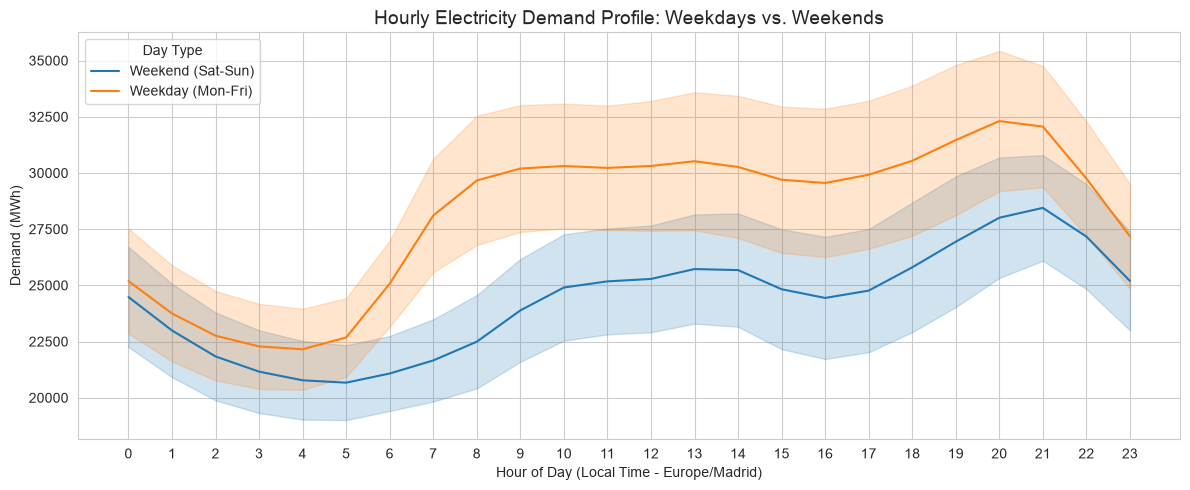

In [11]:
df["day_type"] = df["timestamp_local"].dt.day_of_week.isin([5, 6]).map(
    {False: "Weekday (Mon-Fri)", True: "Weekend (Sat-Sun)"}
)

fig, ax = plt.subplots(figsize=(12, 5))

sns.lineplot(
    data=df,
    x="hour",
    y="demand_mwh",
    hue="day_type",
    estimator="mean",
    errorbar="sd",
    ax=ax,
)

ax.set_title("Hourly Electricity Demand Profile: Weekdays vs. Weekends", fontsize=14)
ax.set_xlabel("Hour of Day (Local Time - Europe/Madrid)")
ax.set_ylabel("Demand (MWh)")
ax.set_xticks(range(0, 24))
ax.legend(title="Day Type")
plt.tight_layout()
plt.show()


## Temperature vs Demand
How the demand reacts to cold or warmth. We fit the points with a order-2 polynomial to see if they fit like they should: peaks at low (heating) and high (AC) temperatures.

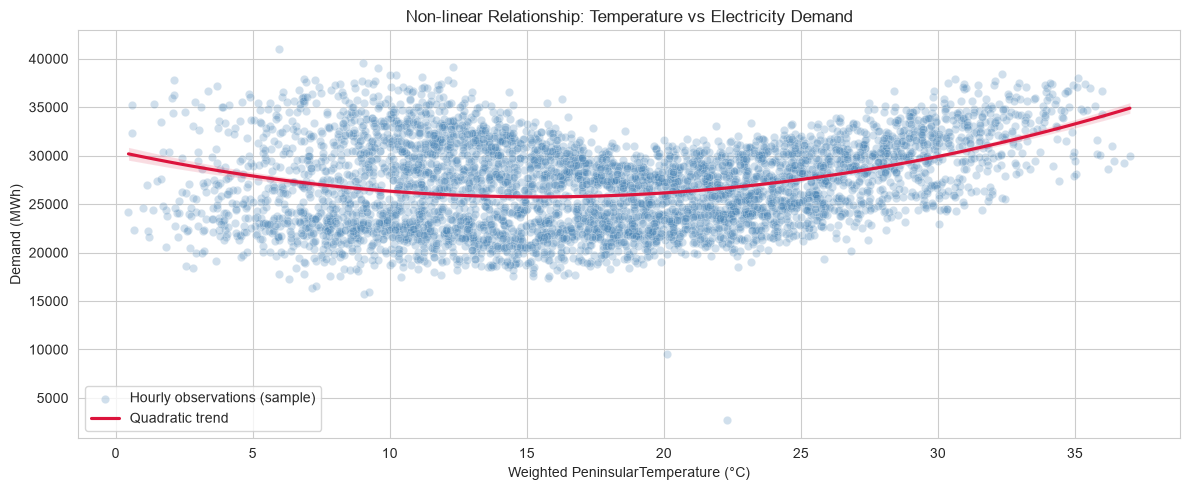

In [6]:
fig, ax = plt.subplots(figsize=(12, 5))

# Sample 5000 points for better visualization and polynomial fitting
df_sample = df.sample(n=5000, random_state=42)

sns.scatterplot(
    data=df_sample,
    x="temperature_2m",
    y="demand_mwh",
    alpha=0.25,
    color="steelblue",
    ax=ax,
    label="Hourly observations (sample)"
)

sns.regplot(
    data=df_sample,
    x="temperature_2m",
    y="demand_mwh",
    scatter=False,
    order=2,
    color="crimson",
    ax=ax,
    label="Quadratic trend"
)

ax.set_title("Non-linear Relationship: Temperature vs Electricity Demand", fontsize=12)
ax.set_xlabel("Weighted PeninsularTemperature (°C)")
ax.set_ylabel("Demand (MWh)")
ax.legend()
plt.tight_layout()
plt.show()

## Autocorrelation

We check the correlation of the actual demand with the demand yesterday (24h) and the past week (168h).

In [7]:
# Compute correlation 
df["lag_24h"] = df["demand_mwh"].shift(24)
df["lag_48h"] = df["demand_mwh"].shift(48)
df["lag_168h"] = df["demand_mwh"].shift(168)

corr_matrix = df[["demand_mwh", "lag_24h", "lag_48h", "lag_168h", "temperature_2m"]].corr()

print("Correlation with target (demand_mwh):")
display(corr_matrix["demand_mwh"].round(3))

Correlation with target (demand_mwh):


demand_mwh        1.000
lag_24h           0.814
lag_48h           0.633
lag_168h          0.891
temperature_2m    0.209
Name: demand_mwh, dtype: float64

## Anomalous data

Previously we have noticed that the minimum registred demand is around 5-10 MWh, which is imposible unless we are treating with the general blackout suffered on April 2025.

In [12]:
anomalies = df[df["demand_mwh"] < 15000]
print(f"Found {len(anomalies)} anomalous hours:")
display(anomalies[["timestamp_utc", "timestamp_local", "demand_mwh", "temperature_2m"]])


Found 13 anomalous hours:


,timestamp_utc,timestamp_local,demand_mwh,temperature_2m
29122,2025-04-28 10:00:00+00:00,2025-04-28 12:00:00+02:00,13998.702,19.452
29123,2025-04-28 11:00:00+00:00,2025-04-28 13:00:00+02:00,518.113,20.765
29124,2025-04-28 12:00:00+00:00,2025-04-28 14:00:00+02:00,1172.419,21.699
29125,2025-04-28 13:00:00+00:00,2025-04-28 15:00:00+02:00,2022.939,22.026
29126,2025-04-28 14:00:00+00:00,2025-04-28 16:00:00+02:00,2764.712,22.308
29127,2025-04-28 15:00:00+00:00,2025-04-28 17:00:00+02:00,3861.053,22.137
29128,2025-04-28 16:00:00+00:00,2025-04-28 18:00:00+02:00,5811.180,21.740
29129,2025-04-28 17:00:00+00:00,2025-04-28 19:00:00+02:00,7343.159,21.062
29130,2025-04-28 18:00:00+00:00,2025-04-28 20:00:00+02:00,9495.675,20.113
29131,2025-04-28 19:00:00+00:00,2025-04-28 21:00:00+02:00,11775.423,18.851
